## Install dependencies
Run the next cell once in the notebook kernel. Git and internet access are required. It installs defSim directly from the project GitHub repository, plus the plotting dependencies. Restart the kernel after installation if prompted. This installs the current GitHub version, not a recovered historical version.


In [10]:
%pip install "git+https://github.com/defSim/defSim.git" matplotlib seaborn


  Cloning https://github.com/defSim/defSim.git to /private/var/folders/3j/3n63wyxd1ksf6ngfh1kzsklm0000gn/T/pip-req-build-fc3qtvnn
  Running command git clone --filter=blob:none --quiet https://github.com/defSim/defSim.git /private/var/folders/3j/3n63wyxd1ksf6ngfh1kzsklm0000gn/T/pip-req-build-fc3qtvnn
  Resolved https://github.com/defSim/defSim.git to commit f7caae76cf41416b1cd4dd1a0f3018a953697721
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done

[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [11]:
import defSim as ds
import networkx as nx
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 12
import seaborn as sns

from defSim.neighbor_selector_sim.neighbor_selector_sim import NeighborSelector
from defSim.tools.CreateOutputTable import OutputTableCreator

from typing import Iterable

In [12]:
# new neighbor selector

class SimilarRankNeighborSelector(NeighborSelector):

    def select_neighbors(self, network: nx.Graph, focal_agent: int, regime: str,
                         set_size_neighbor_selector: int = 1, **kwargs) -> Iterable[int]:

        # sort the neighbors by distance and take set of size 'set_size_neighbor_selector'
        eligible_neighbors = [i for i,d in sorted(network[focal_agent].items(), key=lambda k_v: k_v[1]['dist'])][0:set_size_neighbor_selector]

        if eligible_neighbors == []:
            return []
        else:
            if regime == "one-to-one":
                return [random.choice(eligible_neighbors)]
            elif regime == "one-to-many":
                return eligible_neighbors
            elif regime == "many-to-one":
                return [random.choice(eligible_neighbors)] # careful, this is a hack
            else:
                raise ValueError("You can only select from the options ['one-to-one', 'one-to-many', 'many-to-one']")

In [13]:
# new output measure

class DispersionReporter(OutputTableCreator):

    label = "Dispersion"

    def __init__(self, feature: str = 'f01'):
        super().__init__()
        self.feature = feature     

    def create_output(self, network: nx.Graph, **kwargs):
        """
        ...
        """    
        
        attribute_values = nx.get_node_attributes(network, self.feature).values()
        mu_values = sum(attribute_values) / len(attribute_values)
        dispersion = 2 / len(attribute_values) * sum([abs(i - mu_values) for i in attribute_values])
        
        return(dispersion)

In [14]:
# new output measure

class SpreadReporter(OutputTableCreator):

    label = "Spread"

    def __init__(self, feature: str = 'f01'):
        super().__init__()
        self.feature = feature     

    def create_output(self, network: nx.Graph, **kwargs):
        """
        ...
        """    
        
        attribute_values = nx.get_node_attributes(network, self.feature).values()
        
        return(max(attribute_values) - min(attribute_values))

In [15]:
# new output measure

class CoverageReporter(OutputTableCreator):

    label = "Coverage"

    def __init__(self, feature: str = 'f01'):
        super().__init__()
        self.feature = feature     

    def create_output(self, network: nx.Graph, **kwargs):
        """
        ...
        """    
        
        sortdata = sorted(nx.get_node_attributes(network, self.feature).values())
        
        halo_radius = 0.5 / len(network.nodes)
        lo_bounds = [i - halo_radius for i in sortdata]
        hi_bounds = [i + halo_radius for i in sortdata]

        area_not_covered = 0

        for i in range(len(sortdata)):
            if i == 1:
                if lo_bounds[i] > 0:
                    area_not_covered += lo_bounds[i]
            elif i < (len(sortdata) - 1):
                if lo_bounds[i] > hi_bounds[i-1]:
                    area_not_covered += lo_bounds[i] - hi_bounds[i-1]
            else: #i == len(sortdata)-1
                if hi_bounds[i] < 1:
                    area_not_covered += 1 - hi_bounds[i]
        return(1 - area_not_covered)

In [16]:
seed = np.random.randint(99999)

model = ds.Experiment(
    seed = seed ,
    topology = 'complete_graph' ,
    attributes_initializer = 'random_continuous' ,
    dissimilarity_measure = 'euclidean',
    influenceable_attributes=["f01"],
    neighbor_selector=SimilarRankNeighborSelector(),
    influence_function="weighted_linear",
    max_iterations=1000,
    communication_regime="many-to-one",
    #stop_condition = "pragmatic_convergence",
    output_realizations = ['Basic',
                           ds.tools.OutputMeasures.ClusterFinder(cluster_dissimilarity_threshold=0.1),
                           DispersionReporter(),
                           SpreadReporter(),
                           CoverageReporter()],
    repetitions=10,
    network_parameters = {'n':50},
    attribute_parameters = {'num_features':1},
    influence_parameters = {'homophily':list(np.arange(1.5, 3.05, 0.1)),
                            'convergence_rate':0.5},
    neighbor_parameters = {'set_size_neighbor_selector':[20, 40]}
)

results = model.run()

100%|██████████| 320/320 [00:44<00:00,  7.17it/s]


FileNotFoundError: [Errno 2] No such file or directory: 'output/abm1_illustration.png'

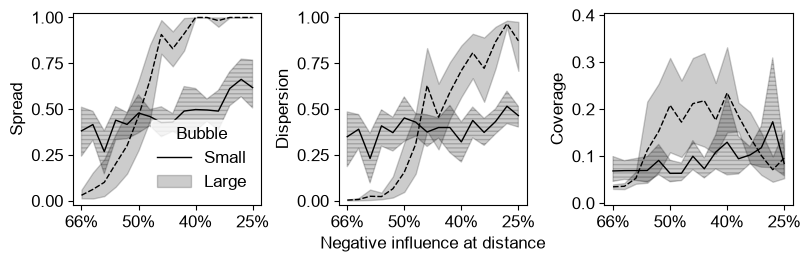

In [17]:
def plot_polarization(data=results):
    fig, axs = plt.subplots(1,3, figsize=[8,2.6])
    fig.tight_layout(w_pad=2)
    sns.lineplot(
        ax=axs[0], data=data, linewidth=1, color='black',
        x="homophily", style="set_size_neighbor_selector", y="Spread")
    sns.lineplot(
        ax=axs[1], data=data, linewidth=1, color='black',
        x="homophily", style="set_size_neighbor_selector", y="Dispersion")
    sns.lineplot(
        ax=axs[2], data=data, linewidth=1, color='black',
        x="homophily", style="set_size_neighbor_selector", y="Coverage")
    axs[0].legend(loc=4, title="Bubble", labels=['Small','Large'], edgecolor='w')
    axs[0].set(xlabel='', ylim=[-0.025,1.025], 
               xticks=[1.5, 2, 2.5, 3], xticklabels=['66%','50%','40%','25%'])
    axs[1].get_legend().remove()
    axs[1].set(xlabel='Negative influence at distance', ylim=[-0.025,1.025], 
               xticks=[1.5, 2, 2.5, 3], xticklabels=['66%','50%','40%','25%'])
    axs[2].get_legend().remove()
    axs[2].set(xlabel='', ylim=[-0.005,0.405], 
               xticks=[1.5, 2, 2.5, 3], xticklabels=['66%','50%','40%','25%'])
    
    axs[0].get_children()[1].set_hatch('----')
    axs[1].get_children()[1].set_hatch('----')
    axs[2].get_children()[1].set_hatch('----')
    
    plt.savefig('output/abm1_illustration.png', dpi=144, bbox_inches = "tight")
    plt.show()

plot_polarization()

In [18]:
seed = np.random.randint(99999)

model = ds.Experiment(
    seed = seed ,
    topology = 'complete_graph' ,
    attributes_initializer = 'random_continuous' ,
    dissimilarity_measure = 'euclidean',
    influenceable_attributes=["f01"],
    neighbor_selector=SimilarRankNeighborSelector(),
    influence_function="weighted_linear",
    max_iterations=1000,
    communication_regime="many-to-one",
    #stop_condition = "pragmatic_convergence",
    output_realizations = ['Basic',
                           'Dispersion',
                           'Spread',
                           'Coverage'
                           #ds.tools.OutputMeasures.ClusterFinder(cluster_dissimilarity_threshold=0.1),
                           #DispersionReporter(),
                           #SpreadReporter(),
                           #CoverageReporter()
                          ],
    repetitions=10,
    network_parameters = {'n':50},
    attribute_parameters = {'num_features':1},
    influence_parameters = {'homophily':1.58,
                            'convergence_rate':0.5},
    neighbor_parameters = {'set_size_neighbor_selector':[i for i in range(0,51)]}
)

results = model.run()

100%|██████████| 510/510 [01:08<00:00,  7.49it/s]


FileNotFoundError: [Errno 2] No such file or directory: 'output/abm2_calibrated.png'

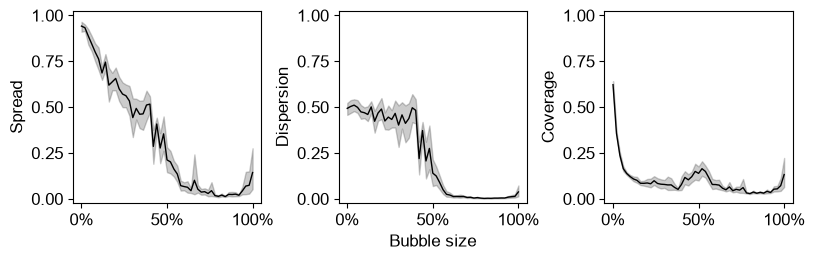

In [19]:
def plot_polarization(data=results):
    fig, axs = plt.subplots(1,3, figsize=[8,2.6])
    fig.tight_layout(w_pad=2)
    sns.lineplot(
        ax=axs[0], data=data, linewidth=1, color='black',
        x="set_size_neighbor_selector", y="Spreadf01")
    sns.lineplot(
        ax=axs[1], data=data, linewidth=1, color='black',
        x="set_size_neighbor_selector", y="Dispersionf01")
    sns.lineplot(
        ax=axs[2], data=data, linewidth=1, color='black',
        x="set_size_neighbor_selector", y="Coveragef01")
    #axs[0].legend(loc=4, title="Bubble", labels=['Small','Large'], edgecolor='w')
    axs[0].set(ylabel='Spread', xlabel='', ylim=[-0.025,1.025], 
               xticks=[0,25,50], xticklabels=['0%','50%','100%'])
    #axs[1].get_legend().remove()
    axs[1].set(ylabel='Dispersion', xlabel='Bubble size', ylim=[-0.025,1.025], 
               xticks=[0,25,50], xticklabels=['0%','50%','100%'])
    #axs[2].get_legend().remove()
    axs[2].set(ylabel='Coverage', xlabel='', ylim=[-0.025,1.025], 
               xticks=[0,25,50], xticklabels=['0%','50%','100%'])
    
    #axs[0].get_children()[1].set_hatch('----')
    #axs[1].get_children()[1].set_hatch('----')
    #axs[2].get_children()[1].set_hatch('----')
    
    plt.savefig('output/abm2_calibrated.png', dpi=144, bbox_inches = "tight")
    plt.show()

plot_polarization()

In [20]:
from defSim.influence_sim.influence_sim import InfluenceOperator
from defSim.dissimilarity_component.dissimilarity_calculator import DissimilarityCalculator
from defSim.tools.NetworkDistanceUpdater import update_dissimilarity

#import warnings

from typing import List


class CalibratedWeightedLinear(InfluenceOperator):

    def __init__(self, regime: str, **kwargs):

        self.regime = regime

        try:
            self.convergence_rate = kwargs["convergence_rate"]
        except KeyError:
            #warnings.warn("convergence_rate not specified, using default value 0.5")
            self.convergence_rate = 0.5
       
        try:
            self.homophily = kwargs["homophily"]
        except KeyError:
            #warnings.warn("homophily not specified, using default value 0")
            self.homophily = 0

        try:
            self.modifiers = kwargs["influence_modifiers"]
        except KeyError:
            self.modifiers = []            

        # check modifiers
        if type(self.modifiers) != list:
            self.modifiers = [self.modifiers]
        if not all([modifier in ["bound", "smooth", "stubborn"] for modifier in self.modifiers]):
            #warnings.warn("Unrecognized modifier in __class__. Only 'smooth' and 'stubborn' are recognized.")
            pass

        self.bi_directional = kwargs.get('bi_directional', False)
        

    def spread_influence(self,
                         network: nx.Graph,
                         agent_i: int,
                         agents_j: List[int] or int,
                         dissimilarity_measure: DissimilarityCalculator,
                         attributes: List[str] = None,
                         **kwargs) -> bool:

        # IMPORTANT BIT !!!
        self.convergence_rate = np.random.normal(0.2087561, 0.10261714, 1) 
        beta = np.random.normal(0.2588109, 0.15177886, 1)
        self.homophily = beta / self.convergence_rate
        # ------------- !!!
        
        if type(agents_j) != list:
            agents_j = [agents_j]

        if attributes is None:
            # if no specific attributes were given, take all of them
            attributes = list(network.nodes[agent_i].keys())

        # variable to return at the end of function
        success = False

        influenced_feature = random.choice(attributes)

        if self.regime != "many-to-one": # it must be "one-to-one" or "one-to-many"
            for neighbor in agents_j:
                # calculate 'opinion' distance on the trait that will be changed
                feature_difference = network.nodes[agent_i][influenced_feature] - \
                                     network.nodes[neighbor][influenced_feature]
                # influence function
                influence = self.convergence_rate * (1 - self.homophily * abs(network.edges[agent_i, neighbor]["dist"])) * \
                    feature_difference
                # apply smoothing
                if "smooth" in self.modifiers:
                    influence = self._apply_smoothing(base_influence = influence, target = neighbor, 
                        influenced_feature = influenced_feature, network = network)
                # apply stubbornness
                if "stubborn" in self.modifiers:
                    influence = self._apply_smoothing(base_influence = influence, target = neighbor, 
                        influenced_feature = influenced_feature, network = network)

                network.nodes[neighbor][influenced_feature] = network.nodes[neighbor][influenced_feature] + influence

                # bounding the opinions to the pre-supposed opinion scale [0,1]
                if network.nodes[neighbor][influenced_feature] > 1: network.nodes[neighbor][influenced_feature] = 1
                if network.nodes[neighbor][influenced_feature] < 0: network.nodes[neighbor][influenced_feature] = 0

                if self.bi_directional == True and self.regime == "one-to-one":
                    # influence function applied again
                    # (note that feature_difference has not been updated after changing neighbor's feature
                    # and feature_difference has to be reversed here)
                    influence = self.convergence_rate * (1 - self.homophily * abs(network.edges[agent_i, neighbor]["dist"])) * \
                    -feature_difference

                    # apply smoothing
                    if "smooth" in self.modifiers:
                        influence = self._apply_smoothing(base_influence = influence, target = agent_i, 
                            influenced_feature = influenced_feature, network = network)
                    # apply stubbornness
                    if "stubborn" in self.modifiers:
                        influence = self._apply_smoothing(base_influence = influence, target = agent_i, 
                            influenced_feature = influenced_feature, network = network)                    

                    network.nodes[agent_i][influenced_feature] = network.nodes[agent_i][influenced_feature] + influence

                    if network.nodes[agent_i][influenced_feature] > 1: network.nodes[agent_i][influenced_feature] = 1
                    if network.nodes[agent_i][influenced_feature] < 0: network.nodes[agent_i][influenced_feature] = 0
                    update_dissimilarity(network, [agent_i, neighbor], dissimilarity_measure, **kwargs)
                else:
                    update_dissimilarity(network, [neighbor], dissimilarity_measure, **kwargs)
                success = True

        else: # applies "many-to-one"
            set_of_influencers = [neighbor for neighbor in agents_j]
            
            if len(set_of_influencers) != 0:
                ## Calculate total influence as average of influence from all neighbors
                influence_values = []
                for neighbor in set_of_influencers:
                    # calculate feature distance on the feature that will be changed
                    feature_difference = network.nodes[neighbor][influenced_feature] - \
                                         network.nodes[agent_i][influenced_feature]

                    # calculate influence
                    influence_values.append(self.convergence_rate * (1 - self.homophily * abs(network.edges[agent_i, neighbor]["dist"])) * \
                        feature_difference)
                
                overall_influence = sum(influence_values) / len(influence_values)

                # apply smoothing to overall influence
                if "smooth" in self.modifiers:
                    influence = self._apply_smoothing(base_influence = overall_influence, target = agent_i, 
                        influenced_feature = influenced_feature, network = network)
                # apply stubbornness to overall influence
                if "stubborn" in self.modifiers:
                    influence = self._apply_smoothing(base_influence = overall_influence, target = agent_i, 
                        influenced_feature = influenced_feature, network = network) 

                network.nodes[agent_i][influenced_feature] = network.nodes[agent_i][influenced_feature] + overall_influence
                
                # bounding the opinions to the pre-supposed opinion scale [0, 1]
                if network.nodes[agent_i][influenced_feature] > 1: network.nodes[agent_i][influenced_feature] = 1
                if network.nodes[agent_i][influenced_feature] < 0: network.nodes[agent_i][influenced_feature] = 0                    
                
                update_dissimilarity(network, [agent_i], dissimilarity_measure, **kwargs)
                success = True

        return success

In [24]:
from defSim.dissimilarity_component.EuclideanDistance import EuclideanDistance

seed = np.random.randint(99999)


model = ds.Experiment(
    seed = seed ,
    topology = 'complete_graph' ,
    attributes_initializer = 'random_continuous' ,
    dissimilarity_measure = 'euclidean',
    influenceable_attributes=["f01"],
    neighbor_selector=SimilarRankNeighborSelector(),
    influence_function=CalibratedWeightedLinear('many-to-one'),
    max_iterations=5000,
    communication_regime="many-to-one",
    #stop_condition = "pragmatic_convergence",
    output_realizations = ['Basic',
                           'Dispersion',
                           'Spread',
                           'Coverage'
                          ],
    repetitions=100,
    network_parameters = {'n':50},
    attribute_parameters = {'num_features':1},
    influence_parameters = {'homophily':1.58,
                            'convergence_rate':0.5},
    neighbor_parameters = {'set_size_neighbor_selector':[10,20,30,40]}
)

results = model.run()

100%|██████████| 400/400 [04:50<00:00,  1.38it/s]


In [25]:
results['Coveragef01'] = [i[0] if type(i) != float else i for i in results['Coveragef01']]
results['Spreadf01'] = [i[0] if type(i) != float else i for i in results['Spreadf01']]
results['Dispersionf01'] = [i[0] if type(i) != float else i for i in results['Dispersionf01']]



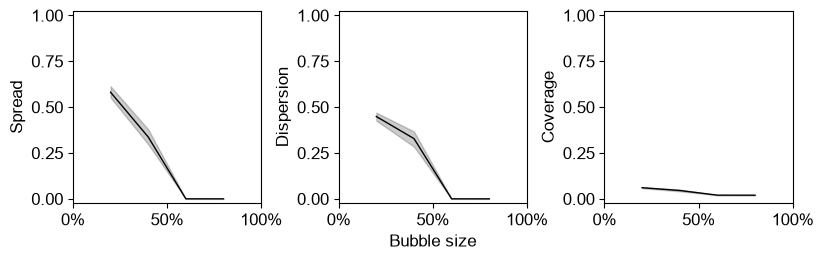

In [26]:
def plot_polarization(data=results):
    fig, axs = plt.subplots(1,3, figsize=[8,2.6])
    fig.tight_layout(w_pad=2)
    sns.lineplot(
        ax=axs[0], data=data, linewidth=1, color='black',
        x="set_size_neighbor_selector", y="Spreadf01")
    sns.lineplot(
        ax=axs[1], data=data, linewidth=1, color='black',
        x="set_size_neighbor_selector", y="Dispersionf01")
    sns.lineplot(
        ax=axs[2], data=data, linewidth=1, color='black',
        x="set_size_neighbor_selector", y="Coveragef01")
    #axs[0].legend(loc=4, title="Bubble", labels=['Small','Large'], edgecolor='w')
    axs[0].set(ylabel='Spread', xlabel='', ylim=[-0.025,1.025], 
               xticks=[0,25,50], xticklabels=['0%','50%','100%'])
    #axs[1].get_legend().remove()
    axs[1].set(ylabel='Dispersion', xlabel='Bubble size', ylim=[-0.025,1.025], 
               xticks=[0,25,50], xticklabels=['0%','50%','100%'])
    #axs[2].get_legend().remove()
    axs[2].set(ylabel='Coverage', xlabel='', ylim=[-0.025,1.025], 
               xticks=[0,25,50], xticklabels=['0%','50%','100%'])
    
    #axs[0].get_children()[1].set_hatch('----')
    #axs[1].get_children()[1].set_hatch('----')
    #axs[2].get_children()[1].set_hatch('----')
    
    #plt.savefig('output/abm2_calibrated.png', dpi=144, bbox_inches = "tight")
    plt.show()

plot_polarization()